In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from adjustText import adjust_text
from collections import defaultdict

# Set the default Seaborn theme
sns.set_theme(style="ticks")

# Load the dataset and parse dates
df = pd.read_csv("../data_jobs.csv", parse_dates=["job_posted_date"])

# Convert string representations of lists into actual Python lists
df["job_skills"] = df["job_skills"].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)
df["job_type_skills"] = df["job_type_skills"].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

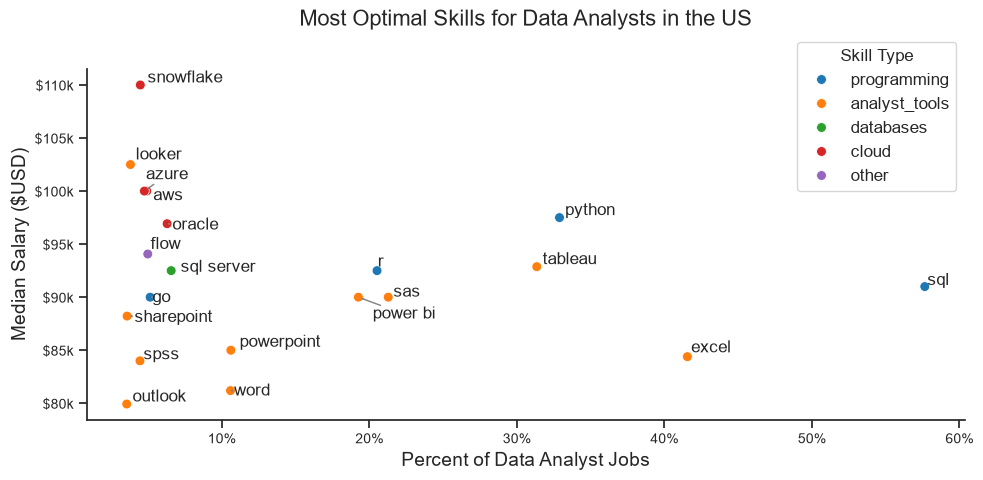

In [ ]:
# Filter Data Analyst jobs in the US and remove rows with missing yearly salaries
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')].dropna(subset='salary_year_avg')

# Count the number of job postings to use as the denominator when calculating percentages
num_postings = len(df_DA_US)

# Expand the job_skills list so that each skill gets its own row
df_explode = df_DA_US.explode('job_skills')

# Group jobs by skill, calculate the number of occurrences and median salary,
# sort by the most frequently requested skills, and keep the top 20
df_plot = (
    df_explode
    .groupby('job_skills')
    .agg(count = ('job_skills', 'size'), median_salary = ('salary_year_avg', 'median'))
    .sort_values(by='count', ascending=False)
    .head(20)
)

# Convert skill counts into percentages of the original job postings
df_plot['count'] /= (num_postings / 100)

# Rename the count column to reflect that it now contains percentages
df_plot.rename(columns={'count': 'per'}, inplace=True)

# Create a dictionary where each skill type maps to a set of its skills
skill_types = defaultdict(set)

# Collect all skills belonging to each skill type across the job postings
for v in df_DA_US["job_type_skills"].dropna():
    for skill_type, skills in v.items():
        for skill in skills:
            skill_types[skill_type].add(skill)  # Use a set to avoid duplicate skills

# Store the skill type corresponding to each skill in df_plot
top_skill_types = []

# Find the skill type for each skill in the DataFrame index
for skill in df_plot.index:
    for skill_type in skill_types:
        if skill in skill_types[skill_type]:
            top_skill_types.append(skill_type)  # Add the matching skill type
            break  # Stop searching once the skill type is found

# Add the skill types as a new column in df_plot
df_plot['type'] = top_skill_types

# Create the scatter plot
plt.figure(figsize=(10, 5))
sns.scatterplot(df_plot, x="per", y="median_salary", hue='type', palette='tab10', s=50)

# Add a label for each skill at its corresponding point
texts = []

for skill, row in df_plot.iterrows():
    texts.append(plt.text(x=row['per'],y=row['median_salary'] ,s=skill)) # type: ignore

# Automatically adjust label positions to reduce overlap and draw connecting arrows
adjust_text(texts, arrowprops={"arrowstyle": "->", "color": "gray", "lw": "1"})

# Format the y-axis salaries in thousands of dollars (e.g., $100k)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"${y/1000:.0f}k"))  # type: ignore

# Format the x-axis values as percentages (e.g., 20%)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))  # type: ignore

# Add the chart title and axis labels
plt.title('Most Optimal Skills for Data Analysts in the US', fontsize=16, y=1.1)
plt.xlabel("Percent of Data Analyst Jobs", fontsize=14)
plt.ylabel("Median Salary ($USD)", fontsize=14)
plt.tick_params(labelsize=10)

# Remove the top and right borders for a cleaner appearance
sns.despine()

# Adjust the layout to prevent chart elements from being clipped
plt.tight_layout()

# Display the final plot
plt.legend(bbox_to_anchor=(1,1.1), fontsize=12, title='Skill Type')
plt.show()